# Task 8 — Understanding Electricity Forecasts
## LSTM interpretation and comparison with the basic neural network

**Task requirement:** apply interpretation and visualization methods, and
compare performance and interpretability with the basic model.

This notebook reuses the **trained Task 7 models**. It does not train or tune
anything. It compares their saved forecasts on the full test period, visualizes
internal activations, and uses Integrated Gradients to explain predictions.
Performance and interpretation are different: a model can be explainable and
still make a poor forecast.

**Run locally:** keep the Task 7 output folder beside this notebook.
**Run in Colab:** upload the Task 7 artifact ZIP to the Files sidebar, name it
`task7_artifacts.zip`, then Run all. No raw dataset download or retraining is
required. The default explanation sample is only 32 examples to limit compute.
Explanations and report files are written to a new `task8_outputs` folder.

In [1]:
import importlib.util
import subprocess
import sys

requirements = {"tensorflow": "tensorflow==2.20.0", "numpy": "numpy>=1.26,<3",
                "pandas": "pandas>=2.2,<3", "matplotlib": "matplotlib>=3.8,<4",
                "sklearn": "scikit-learn>=1.5,<2", "joblib": "joblib>=1.4,<2"}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

## 1. Load the completed Task 7 run

We load the compact stacked LSTM and the basic feed-forward network, along
with their saved scalers and examples. Loading restores their learned weights;
it does not create a newly trained model. A smoke-test run is rejected.

In [2]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import hashlib
import json
import shutil
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

SEED = 42
GLOBAL_EXAMPLES = 32
IG_INITIAL_STEPS, IG_MAX_STEPS = 64, 256
IG_ABS_TOL, IG_REL_TOL = 0.001, 0.01       # kW and relative forecast-difference tolerance
keras.utils.set_random_seed(SEED)
try:
    tf.config.threading.set_intra_op_parallelism_threads(min(8, os.cpu_count() or 2))
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass

RUN_NAME = "full_20261004T223051_253137Z"
ARTIFACT_DIR = Path("task7_outputs") / RUN_NAME
if not ARTIFACT_DIR.exists():
    candidates = [Path("task7_artifacts.zip"), Path(f"{RUN_NAME}.zip"),
                  Path("task7_outputs") / f"{RUN_NAME}.zip"]
    source_zip = next((p for p in candidates if p.is_file()), None)
    if source_zip is None:
        raise FileNotFoundError("Upload the completed Task 7 ZIP as task7_artifacts.zip, or set ARTIFACT_DIR.")
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(source_zip) as z:
        # Refuse archive entries that escape the intended extraction folder.
        base = ARTIFACT_DIR.resolve()
        for entry in z.infolist():
            if not (base / entry.filename).resolve().is_relative_to(base):
                raise ValueError("Unsafe archive member path.")
        z.extractall(base)

manifest = json.loads((ARTIFACT_DIR / "manifest.json").read_text(encoding="utf-8"))
assert manifest["run_mode"] == "full", "Use completed full-data models, not smoke-test artifacts."
assert manifest["sequence_length"] == 96 and manifest["horizon_steps"] == 4
OUTPUT_DIR = Path("task8_outputs") / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

models = {"LSTM": keras.models.load_model(ARTIFACT_DIR / "task7_lstm.keras", compile=False),
          "Basic neural network": keras.models.load_model(ARTIFACT_DIR / "task7_basic_mlp.keras", compile=False)}
scaler = joblib.load(ARTIFACT_DIR / "power_scaler.joblib")
POWER_MEAN, POWER_STD = float(scaler.mean_[0]), float(scaler.scale_[0])
with np.load(ARTIFACT_DIR / "task8_examples.npz", allow_pickle=False) as data:
    examples = {key: data[key] for key in data.files}
X = {"history": examples["explain_history"], "context": examples["explain_context"]}
background = {"history": examples["background_history"], "context": examples["background_context"]}
target_times = pd.to_datetime(examples["explain_target_timestamps_ns"])
actual = examples["explain_actual_kw"]
history_features = manifest["history_features"]
context_features = manifest["context_features"]
assert all(np.isfinite(value).all() for value in [*X.values(), *background.values(), actual])
assert X["history"].shape[1:] == (96, len(history_features))
assert X["context"].shape[1] == len(context_features)
print("Loaded trained models; no training will run.")
print("Saved explanation examples:", len(actual), "| Training reference examples:", len(background["history"]))
print("Outputs:", OUTPUT_DIR.resolve())

Loaded trained models; no training will run.
Saved explanation examples: 256 | Training reference examples: 128
Outputs: C:\Users\Gaurav Choithramani\Desktop\cil\task8_outputs\run_20261004T224434_997783Z


## 2. Verify predictions and compare full-test performance

MAE is average absolute error; RMSE penalizes large errors more strongly.
R² compares squared error with predicting the test targets' mean. Higher is
better, but an R² near 0.40 is modest, not excellent.

Metrics below use **all 18,889 saved test forecasts**, not the smaller explanation
sample. We also check that the reloaded models reproduce all 256 saved example
predictions and that their actual values/timestamps match the forecast file.

task8.ipynb cell 5:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.


,MAE_kW,RMSE_kW,R2,Test_samples,Parameters
Model,,,,,
LSTM,0.4269,0.6182,0.3999,18889,9249
Basic neural network,0.4407,0.6235,0.3896,18889,40129
Persistence,0.5143,0.8055,-0.0188,18889,0
Daily seasonal,0.6070,0.9129,-0.3084,18889,0
Weekly seasonal,0.6425,0.9458,-0.4046,18889,0


LSTM RMSE improvement versus basic network: 0.84%.
All 256 reloaded-model example predictions match the saved Task 7 forecasts.


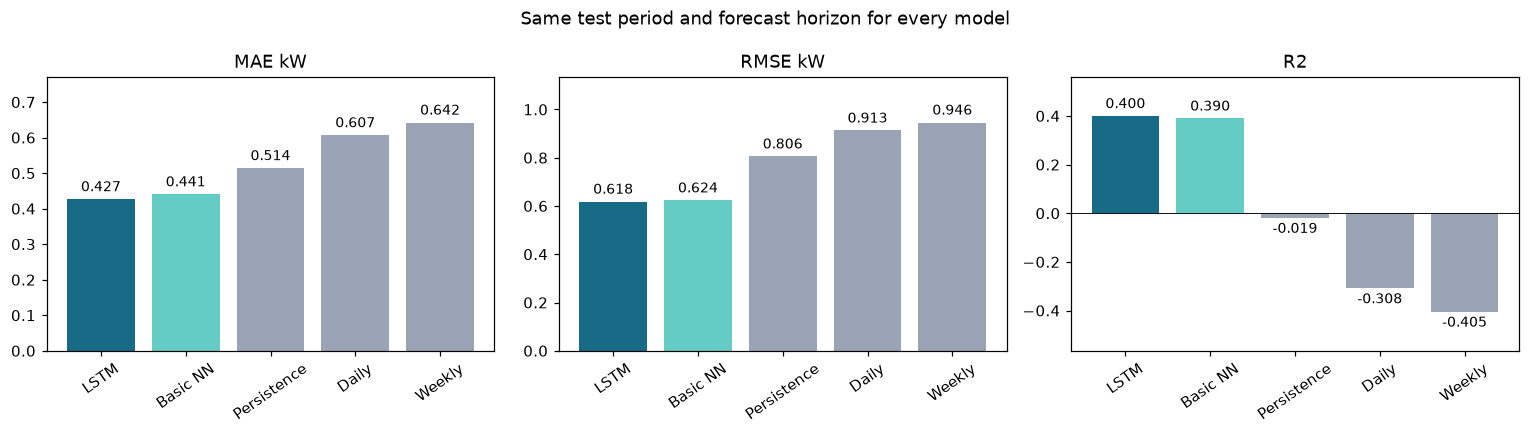

In [3]:
def predict_kw(network, inputs):
    # Exactly the Task 7 output transformation, including the non-negative bound.
    return np.maximum(network(inputs, training=False).numpy().reshape(-1) * POWER_STD + POWER_MEAN, 0)

saved = pd.read_csv(ARTIFACT_DIR / "test_predictions.csv", parse_dates=["Forecast_origin", "Target_interval_end"])
assert saved["Target_interval_end"].is_unique
assert len(saved) == manifest["used_split_counts"]["test"]
assert ((saved["Target_interval_end"] - saved["Forecast_origin"]) == pd.Timedelta(hours=1)).all()
selected_name = manifest["selection"]["selected_lstm"]
columns = {"LSTM": f"{selected_name}_kW", "Basic neural network": "basic_mlp_kW",
           "Persistence": "Persistence_kW", "Daily seasonal": "Daily seasonal_kW",
           "Weekly seasonal": "Weekly seasonal_kW"}
matched = saved.set_index("Target_interval_end").loc[target_times]
np.testing.assert_allclose(actual, matched["Actual_kW"], atol=1e-6)
predictions = {name: predict_kw(network, X) for name, network in models.items()}
for name, prediction in predictions.items():
    np.testing.assert_allclose(prediction, matched[columns[name]], atol=2e-5, rtol=2e-5)

rows = []
for name, column in columns.items():
    y, p = saved["Actual_kW"], saved[column]
    rows.append({"Model": name, "MAE_kW": mean_absolute_error(y, p),
                 "RMSE_kW": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p),
                 "Test_samples": len(y),
                 "Parameters": models[name].count_params() if name in models else 0})
comparison = pd.DataFrame(rows).set_index("Model")
comparison.to_csv(OUTPUT_DIR / "full_test_comparison.csv")
display(comparison.round(4))
gain_vs_basic = 100 * (1 - comparison.loc["LSTM", "RMSE_kW"] / comparison.loc["Basic neural network", "RMSE_kW"])
print(f"LSTM RMSE improvement versus basic network: {gain_vs_basic:.2f}%.")
print("All 256 reloaded-model example predictions match the saved Task 7 forecasts.")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = ["LSTM", "Basic NN", "Persistence", "Daily", "Weekly"]
for ax, metric in zip(axes, ["MAE_kW", "RMSE_kW", "R2"]):
    values = comparison[metric].to_numpy()
    bars = ax.bar(labels, values, color=["#176B87", "#64CCC5", "#9BA4B5", "#9BA4B5", "#9BA4B5"])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_title(metric.replace("_", " "))
    ax.tick_params(axis="x", rotation=35)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.margins(y=0.20)
fig.suptitle("Same test period and forecast horizon for every model")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "performance_comparison.png", dpi=140)
plt.show()

## 3. Inspect three contrasting forecasts

Cases are selected by an explicit rule from the 256 saved examples:
the smallest LSTM absolute error, the median absolute error, and the largest
underprediction among high-demand examples (using Task 7's training-derived
threshold). These are **diagnostic cases**, not an unbiased estimate of accuracy.
The full-test table above is the accuracy evidence.

,Case,Example_position,Target_time,Actual_kW,LSTM_kW,Basic_kW,LSTM_absolute_error_kW
0,Good forecast,12,2010-05-04 00:15:00,0.4361,0.4343,0.5514,0.0019
1,Typical error,126,2010-07-31 00:15:00,0.2100,0.4625,0.4570,0.2525
2,Missed high demand,204,2010-10-18 12:15:00,4.6539,2.1336,1.8013,2.5202


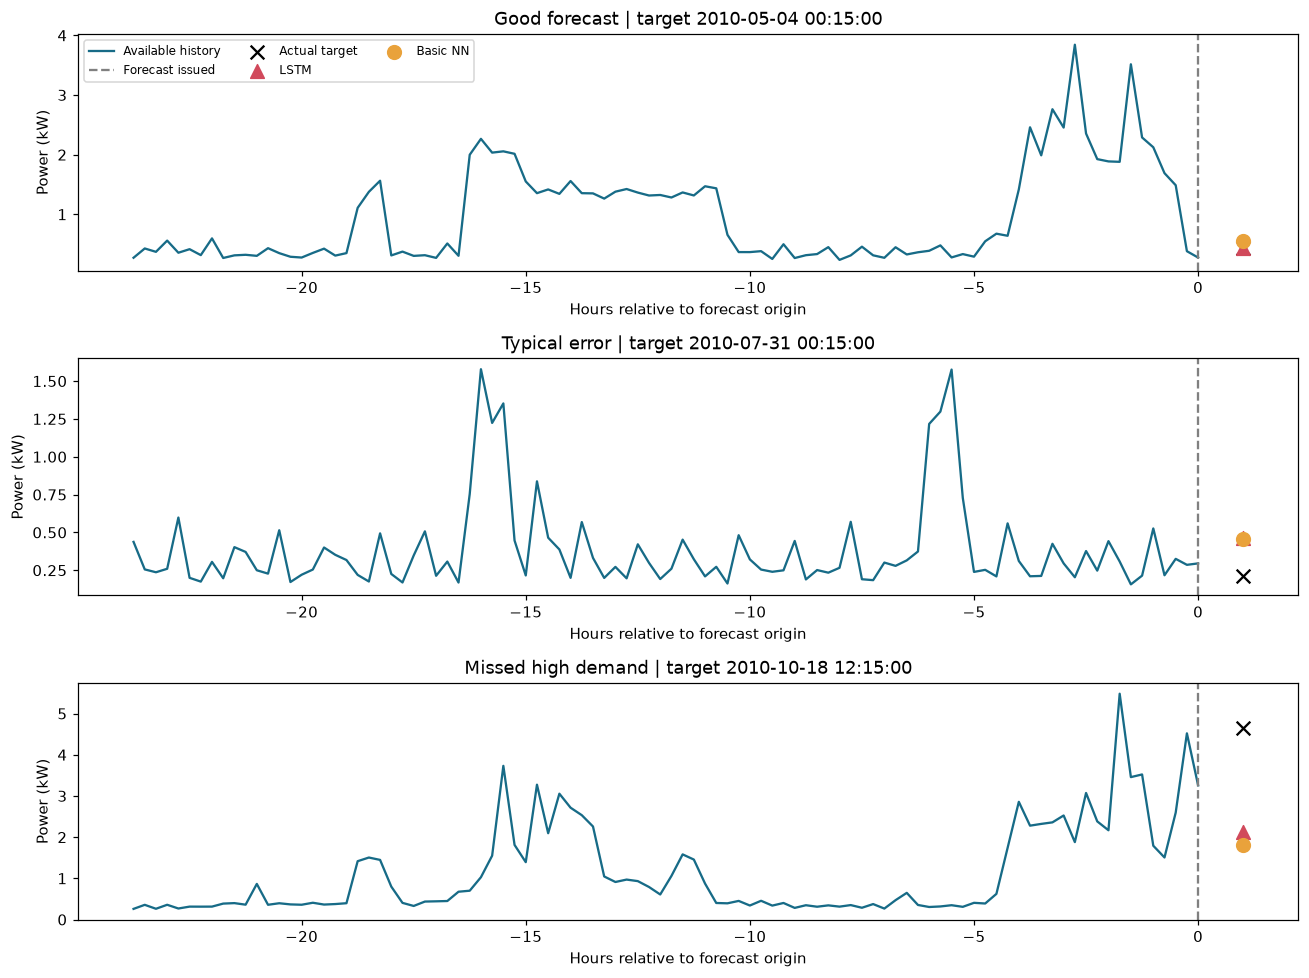

In [4]:
absolute_errors = np.abs(actual - predictions["LSTM"])
ordered = np.argsort(absolute_errors)
peak_candidates = np.flatnonzero(actual >= manifest["peak_threshold_kw"])
if not len(peak_candidates):
    peak_candidates = np.arange(len(actual))
missed_peak = int(peak_candidates[np.argmax((actual - predictions["LSTM"])[peak_candidates])])
cases = {"Good forecast": int(ordered[0]), "Typical error": int(ordered[len(ordered)//2]),
         "Missed high demand": missed_peak}
case_table = pd.DataFrame([
    {"Case": label, "Example_position": i, "Target_time": target_times[i], "Actual_kW": actual[i],
     "LSTM_kW": predictions["LSTM"][i], "Basic_kW": predictions["Basic neural network"][i],
     "LSTM_absolute_error_kW": absolute_errors[i]} for label, i in cases.items()
])
case_table.to_csv(OUTPUT_DIR / "diagnostic_cases.csv", index=False)
display(case_table.round(4))
hours = np.arange(-95, 1) / 4
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (label, i) in zip(axes, cases.items()):
    ax.plot(hours, X["history"][i, :, 0] * POWER_STD + POWER_MEAN, color="#176B87", label="Available history")
    ax.axvline(0, linestyle="--", color="grey", label="Forecast issued")
    for value, marker, color, text in [(actual[i], "x", "black", "Actual target"),
                                      (predictions["LSTM"][i], "^", "#D1495B", "LSTM"),
                                      (predictions["Basic neural network"][i], "o", "#E9A23B", "Basic NN")]:
        ax.scatter([1], [value], marker=marker, color=color, s=80, label=text, zorder=5)
    ax.set(title=f"{label} | target {target_times[i]}", ylabel="Power (kW)", xlabel="Hours relative to forecast origin")
axes[0].legend(loc="upper left", ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "forecast_cases.png", dpi=140)
plt.show()

## 4. Visualize internal activations

An activation is an internal numerical response of a neuron. The first LSTM
layer produces **32 responses at each of 96 time steps**. Its heatmap shows how
the learned representation evolves as the network reads the history.

The basic network's first dense layer produces **64 responses per example**,
with no separate recurrent time axis. A smaller parameter count does not make
the LSTM easier to explain: its recurrent calculations still evolve over time.
Bright colors do not establish feature importance, and neuron numbers do not
have automatic meanings such as “AC usage” or “occupancy.” These are hidden
activations, **not attention weights**. Neither model has an attention layer.

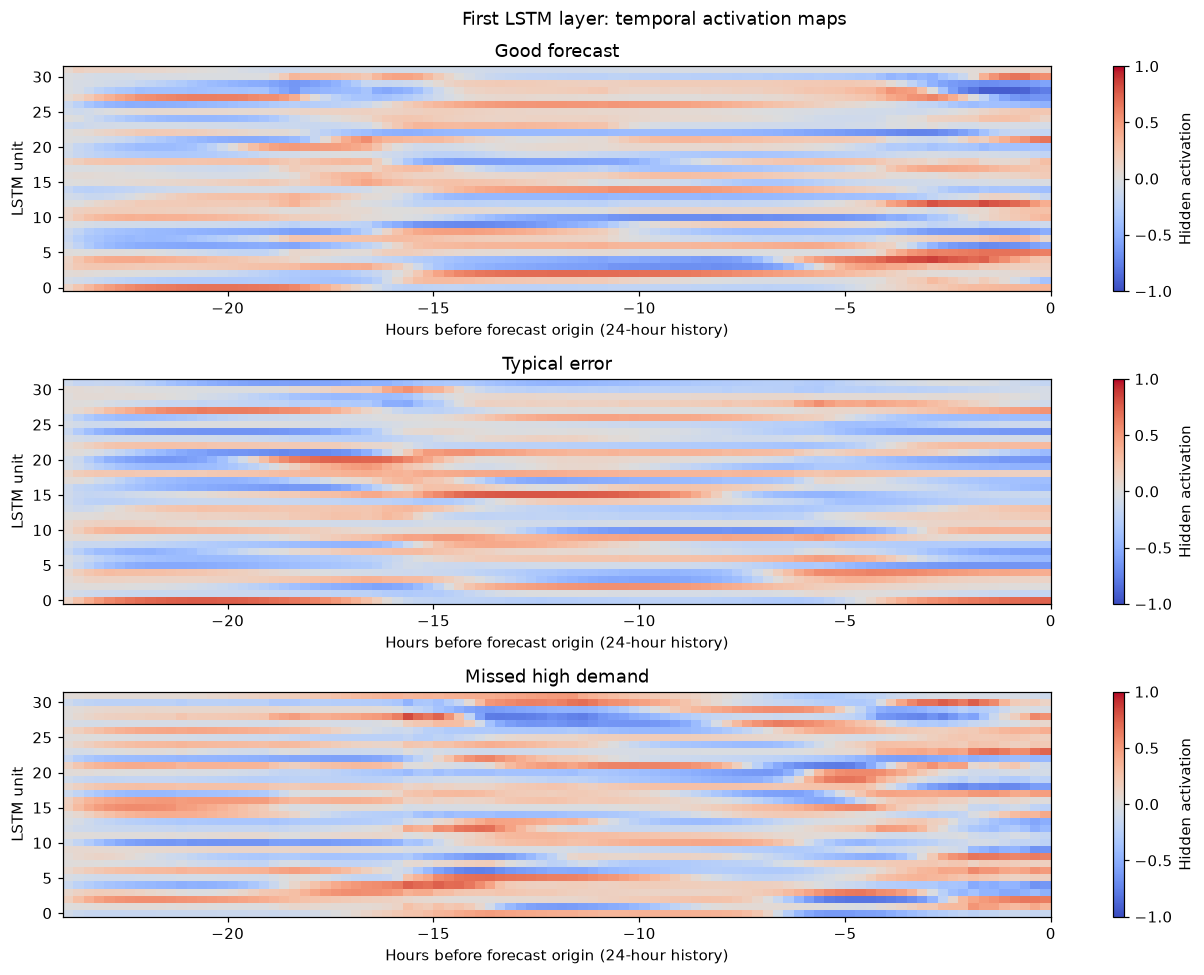

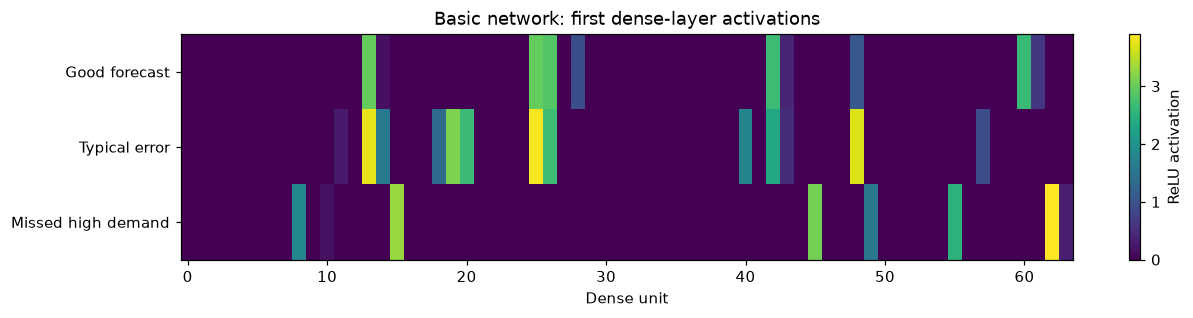

In [5]:
case_ids = np.array(list(cases.values()))
case_inputs = {key: value[case_ids] for key, value in X.items()}
activation_arrays = {}
for name, layer_name in [("LSTM", "lstm_temporal_features"), ("Basic neural network", "dense_features")]:
    network = models[name]
    probe = keras.Model(inputs=network.input, outputs=network.get_layer(layer_name).output)
    activation_arrays[name] = probe(case_inputs, training=False).numpy()

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (label, activation) in zip(axes, zip(cases, activation_arrays["LSTM"])):
    image = ax.imshow(activation.T, aspect="auto", origin="lower", cmap="coolwarm", vmin=-1, vmax=1,
                      extent=[-24, 0, -0.5, activation.shape[1]-0.5])
    ax.set(title=label, xlabel="Hours before forecast origin (24-hour history)", ylabel="LSTM unit")
    fig.colorbar(image, ax=ax, label="Hidden activation")
fig.suptitle("First LSTM layer: temporal activation maps")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lstm_activations.png", dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
image = ax.imshow(activation_arrays["Basic neural network"], aspect="auto", cmap="viridis")
ax.set_yticks(range(3), labels=list(cases))
ax.set(xlabel="Dense unit", title="Basic network: first dense-layer activations")
fig.colorbar(image, ax=ax, label="ReLU activation")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "basic_activations.png", dpi=140)
plt.show()
np.savez_compressed(OUTPUT_DIR / "activations.npz", lstm=activation_arrays["LSTM"],
                    basic=activation_arrays["Basic neural network"], example_positions=case_ids)

## 5. Explain forecasts using Integrated Gradients

Integrated Gradients (IG) asks: **which input differences move this forecast
away from a reference forecast?** It follows the model between a reference
input and the selected input, adding up gradient contributions along that path.
Positive contributions raise the forecast relative to the reference; negative
contributions lower it. Contributions are measured in **kW** here, including
the same inverse scaling and non-negative output rule used in Task 7.

The reference is a real **training** example whose mean historical power is
nearest the median of the saved training background examples. Both models use
exactly the same reference. It represents one historical situation, not zero
consumption or a universal “normal household.” No test example sets the reference.

IG is approximate. We check whether all contributions sum to the difference
between the two forecasts, refining the integration up to 256 steps if needed.
This **completeness check** tests numerical consistency, not whether an
explanation is a true causal account. The method follows the
[TensorFlow Integrated Gradients tutorial](https://www.tensorflow.org/tutorials/interpretability/integrated_gradients).

Limitations: results depend on the reference. Interpolated calendar and missing
flags need not describe real situations. Historical readings and derived lag/
average features overlap, so attribution credit can be shared between them.
Explanations describe the fitted model and cannot prove causes of consumption.

In [6]:
background_means = background["history"][:, :, 0].mean(axis=1)
reference_id = int(np.argmin(np.abs(background_means - np.median(background_means))))
reference = {key: value[reference_id] for key, value in background.items()}
print("Reference training target index:", int(examples["background_indices"][reference_id]))

def make_gradient_function(network, mean, scale):
    @tf.function(reduce_retracing=True)
    def gradients(history, context):
        with tf.GradientTape() as tape:
            tape.watch([history, context])
            output = tf.nn.relu(network({"history": history, "context": context}, training=False) * scale + mean)
            total = tf.reduce_sum(output)
        return tape.gradient(total, [history, context])
    return gradients

def integrated_gradients(gradient_function, inputs, baseline, steps=64):
    alpha = np.linspace(0, 1, steps+1, dtype=np.float32)
    dh = np.asarray(inputs["history"] - baseline["history"], dtype=np.float32)
    dc = np.asarray(inputs["context"] - baseline["context"], dtype=np.float32)
    path_h = baseline["history"][None] + alpha[:, None, None] * dh[None]
    path_c = baseline["context"][None] + alpha[:, None] * dc[None]
    gh, gc = gradient_function(tf.constant(path_h), tf.constant(path_c))
    gh, gc = gh.numpy(), gc.numpy()
    # Trapezoidal numerical integration; endpoints receive half weight.
    return {"history": dh * ((gh[:-1]+gh[1:])/2).mean(axis=0),
            "context": dc * ((gc[:-1]+gc[1:])/2).mean(axis=0)}

# Independent check on a known linear function: IG should be weight * input difference.
def linear_gradients(h, c):
    return tf.ones_like(h)*2, tf.ones_like(c)*3
toy = {"history": np.ones((2, 1), np.float32), "context": np.ones(2, np.float32)}
zero = {key: np.zeros_like(value) for key, value in toy.items()}
toy_ig = integrated_gradients(linear_gradients, toy, zero, steps=8)
np.testing.assert_allclose(toy_ig["history"], 2)
np.testing.assert_allclose(toy_ig["context"], 3)
zero_ig = integrated_gradients(linear_gradients, toy, toy, steps=8)
assert all(np.count_nonzero(value) == 0 for value in zero_ig.values())

global_ids = np.linspace(0, len(actual)-1, min(GLOBAL_EXAMPLES, len(actual)), dtype=int)
explain_ids = np.unique(np.r_[global_ids, case_ids])
attributions, completeness_rows, reference_forecasts = {}, [], {}
for name, network in models.items():
    grad_fn = make_gradient_function(network, POWER_MEAN, POWER_STD)
    reference_forecasts[name] = float(predict_kw(network, {key: value[None] for key, value in reference.items()})[0])
    attributions[name] = {}
    for i in explain_ids:
        inputs = {key: value[i] for key, value in X.items()}
        delta = float(predictions[name][i] - reference_forecasts[name])
        tolerance = IG_ABS_TOL + IG_REL_TOL * abs(delta)
        steps = IG_INITIAL_STEPS
        while True:
            ig = integrated_gradients(grad_fn, inputs, reference, steps)
            contribution_sum = float(sum(np.sum(v, dtype=np.float64) for v in ig.values()))
            residual = abs(contribution_sum - delta)
            if residual <= tolerance or steps >= IG_MAX_STEPS:
                break
            steps = min(2*steps, IG_MAX_STEPS)
        attributions[name][int(i)] = ig
        completeness_rows.append({"Model": name, "Example_position": int(i), "Steps": steps,
                                  "Prediction_minus_reference_kW": delta, "Attribution_sum_kW": contribution_sum,
                                  "Absolute_residual_kW": residual, "Tolerance_kW": tolerance,
                                  "Within_tolerance": bool(residual <= tolerance)})
    print(name, ": explained", len(explain_ids), "examples.")
completeness = pd.DataFrame(completeness_rows)
completeness.to_csv(OUTPUT_DIR / "ig_completeness_checks.csv", index=False)
display(completeness.groupby("Model").agg(Checks=("Within_tolerance", "size"),
                                         Passed=("Within_tolerance", "sum"),
                                         Max_residual_kW=("Absolute_residual_kW", "max")))
if not completeness["Within_tolerance"].all():
    print("Some IG approximations did not meet tolerance. Inspect ig_completeness_checks.csv; interpret small contributions cautiously.")

Reference training target index: 15416


Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: expected exactly one node, got [<gast.gast.Expr object at 0x0000013D6E572250>, <gast.gast.Import object at 0x0000013D73701850>, <gast.gast.Import object at 0x0000013D736E3950>, <gast.gast.Import object at 0x0000013D7373F710>, <gast.gast.Import object at 0x0000013D7373F5D0>, <gast.gast.Import object at 0x0000013D7373F450>, <gast.gast.Import object at 0x0000013D7373F2D0>, <gast.gast.Import object at 0x0000013D7373F150>, <gast.gast.Import object at 0x0000013D7373EFD0>, <gast.gast.ImportFrom object at 0x0000013D7373EE90>, <gast.gast.Expr object at 0x0000013D73158350>, <gast.gast.Expr object at 0x0000013D6D4292D0>, <gast.gast.Import object at 0x0000013D7373E4D0>, <gast.gast.Import object at 0x0000013D7373E390>, <gast.gast.Assign object at 0x0000013D73694A50>, <gast.gast.Assign object at 0x0000013D7373D9D0>, <gast.gast.Expr obj

LSTM : explained 35 examples.


Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: expected exactly one node, got [<gast.gast.Expr object at 0x0000013D73726CD0>, <gast.gast.Import object at 0x0000013D7511E350>, <gast.gast.Import object at 0x0000013D7511E210>, <gast.gast.Import object at 0x0000013D7511E090>, <gast.gast.Import object at 0x0000013D7511DF10>, <gast.gast.Import object at 0x0000013D7511DD50>, <gast.gast.Import object at 0x0000013D7511DB90>, <gast.gast.Import object at 0x0000013D7511DA50>, <gast.gast.Import object at 0x0000013D7511D8D0>, <gast.gast.ImportFrom object at 0x0000013D7511D7D0>, <gast.gast.Expr object at 0x0000013D75059750>, <gast.gast.Expr object at 0x0000013D73B410D0>, <gast.gast.Import object at 0x0000013D7511CB50>, <gast.gast.Import object at 0x0000013D7511CA50>, <gast.gast.Assign object at 0x0000013D7511C090>, <gast.gast.Assign object at 0x0000013D75134290>, <gast.gast.Expr obj

Basic neural network : explained 35 examples.


,Checks,Passed,Max_residual_kW
Model,,,
Basic neural network,35,31,0.016264
LSTM,35,35,0.012803


Some IG approximations did not meet tolerance. Inspect ig_completeness_checks.csv; interpret small contributions cautiously.


## 6. Compare influential inputs across the explanation sample

The global plots use 32 evenly spaced saved examples; diagnostic cases do not
change that sample. These are sample-based summaries, not full-population
feature rankings. The score is mean absolute attribution relative to the
chosen training reference, not an accuracy improvement or a percentage.

For each historical channel, magnitudes are added over its 96 time steps.
Such grouped totals contain more values than one context feature and can be
larger for that reason. The time chart shows **only the direct historical
power channel**; context lags and rolling statistics can contain additional
information about the same readings. Neither chart is an attention map.

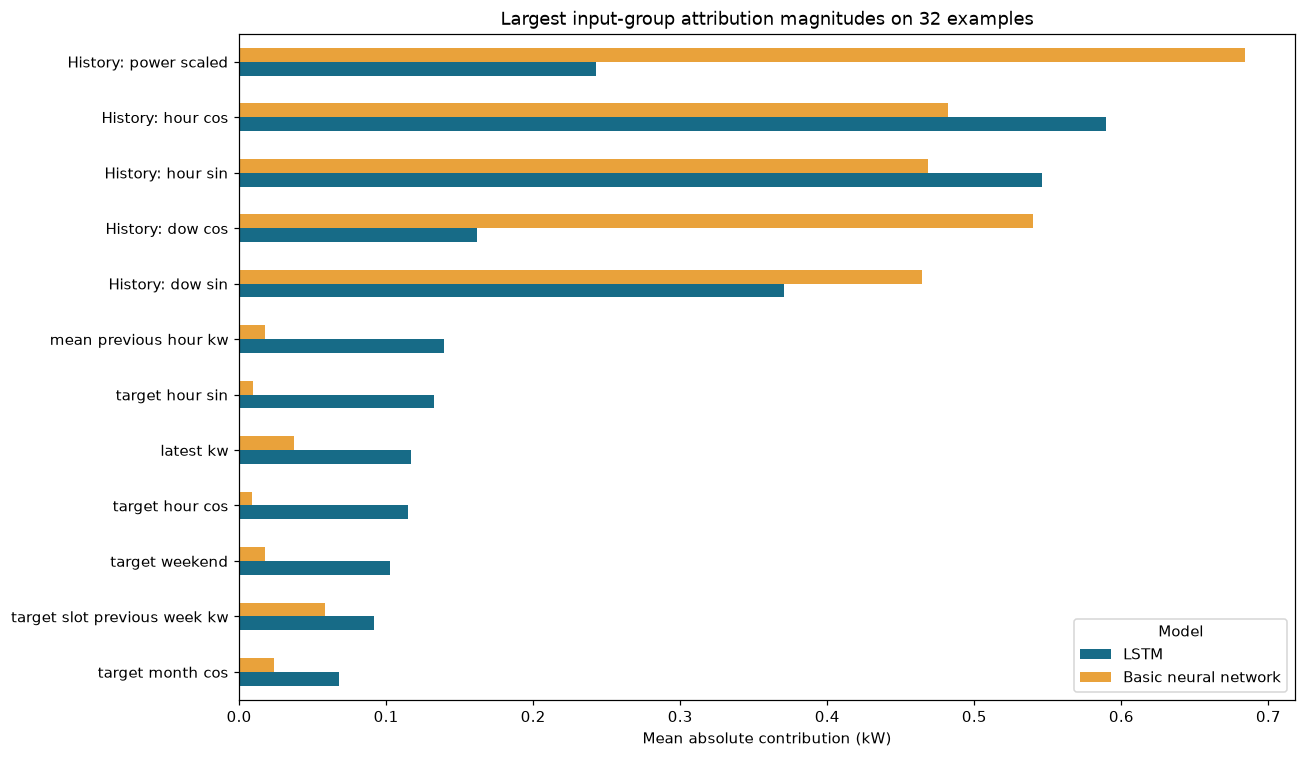

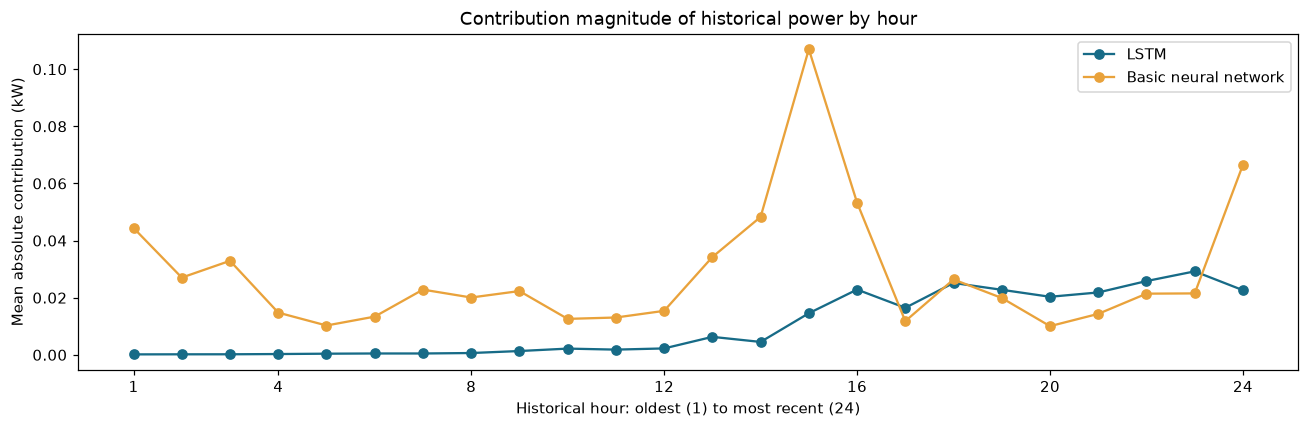

In [7]:
group_names = ["History: " + s.replace("_", " ") for s in history_features] + [s.replace("_", " ") for s in context_features]
importance_rows, time_rows = [], []
for name in models:
    hist = np.stack([attributions[name][int(i)]["history"] for i in global_ids])
    ctx = np.stack([attributions[name][int(i)]["context"] for i in global_ids])
    importance = np.r_[np.abs(hist).sum(axis=1).mean(axis=0), np.abs(ctx).mean(axis=0)]
    for feature, value in zip(group_names, importance):
        importance_rows.append({"Model": name, "Input_group": feature, "Mean_absolute_attribution_kW": float(value)})
    # 24 consecutive one-hour blocks, four quarter-hour contributions per block.
    time_importance = np.abs(hist[:, :, 0]).reshape(len(global_ids), 24, 4).sum(axis=2).mean(axis=0)
    for hour, value in enumerate(time_importance, 1):
        time_rows.append({"Model": name, "Historical_hour_oldest_to_newest": hour,
                          "Mean_absolute_attribution_kW": float(value)})
importance_table = pd.DataFrame(importance_rows)
time_table = pd.DataFrame(time_rows)
importance_table.to_csv(OUTPUT_DIR / "sample_input_attributions.csv", index=False)
time_table.to_csv(OUTPUT_DIR / "sample_temporal_attributions.csv", index=False)
wide = importance_table.pivot(index="Input_group", columns="Model", values="Mean_absolute_attribution_kW")
top_groups = wide.max(axis=1).nlargest(12).index[::-1]
fig, ax = plt.subplots(figsize=(12, 7))
wide.loc[top_groups, ["LSTM", "Basic neural network"]].plot.barh(ax=ax, color=["#176B87", "#E9A23B"])
ax.set(title="Largest input-group attribution magnitudes on 32 examples", xlabel="Mean absolute contribution (kW)", ylabel="")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "input_attribution_comparison.png", dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
for name, color in [("LSTM", "#176B87"), ("Basic neural network", "#E9A23B")]:
    part = time_table[time_table["Model"].eq(name)]
    ax.plot(part["Historical_hour_oldest_to_newest"], part["Mean_absolute_attribution_kW"], marker="o", label=name, color=color)
ax.set(title="Contribution magnitude of historical power by hour", xlabel="Historical hour: oldest (1) to most recent (24)",
       ylabel="Mean absolute contribution (kW)", xticks=[1, 4, 8, 12, 16, 20, 24])
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "temporal_attribution_comparison.png", dpi=140)
plt.show()

## 7. Explain individual successes and errors

Signed contributions below show which input groups push each forecast above
or below its reference forecast. Historical contributions are summed over time
to give each channel's **net** contribution here; opposite signs can cancel.
All remaining groups are combined as “Other inputs,” so the chart retains the
full attribution sum. A plausible explanation of a missed peak is still an
explanation of a wrong forecast, not proof that the model is reliable.

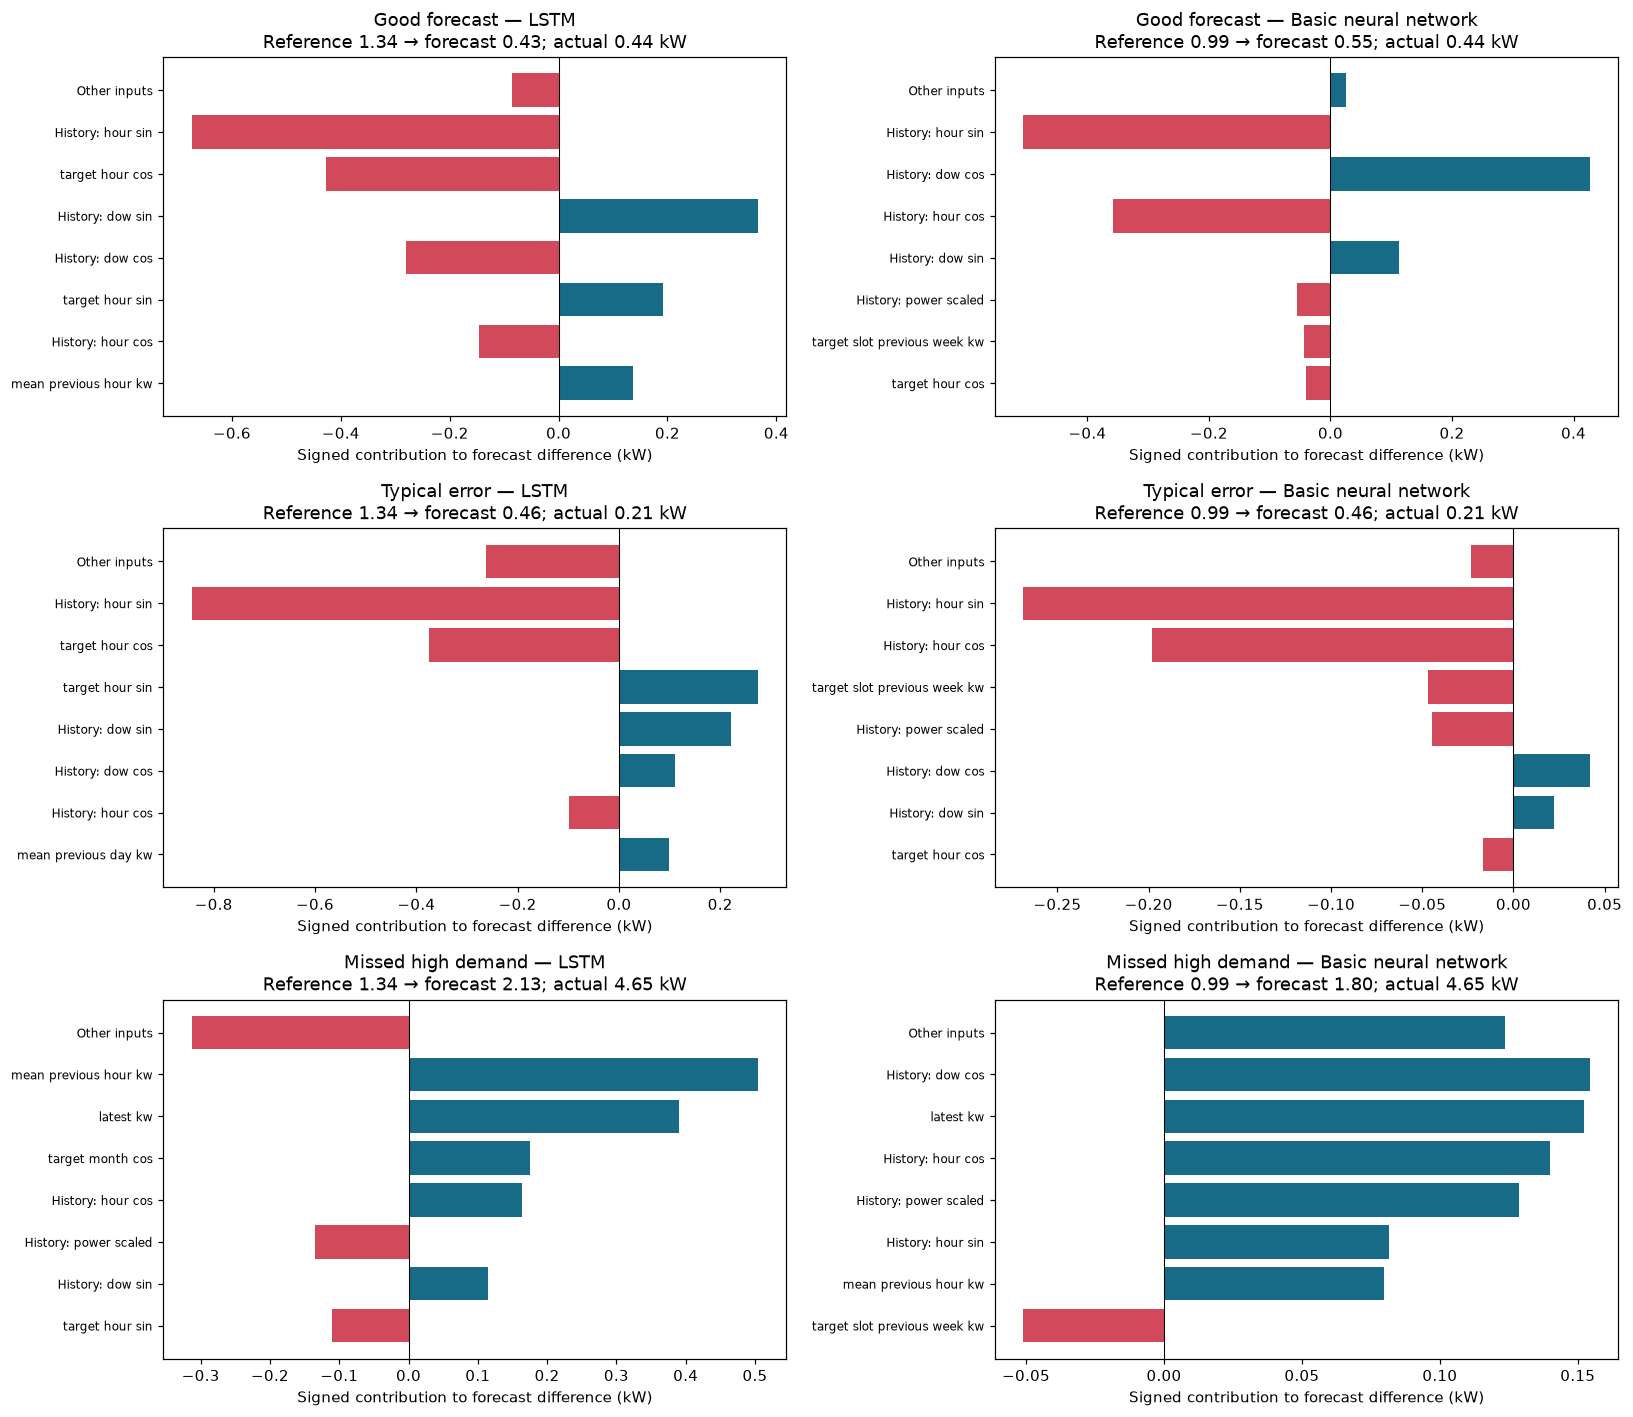

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
local_rows = []
for row, (case_label, i) in enumerate(cases.items()):
    for col, name in enumerate(models):
        ig = attributions[name][i]
        values = np.r_[ig["history"].sum(axis=0), ig["context"]]
        keep = np.argsort(np.abs(values))[-7:]
        other = float(values.sum() - values[keep].sum())
        labels = [group_names[j] for j in keep] + ["Other inputs"]
        displayed = np.r_[values[keep], other]
        ax = axes[row, col]
        ax.barh(labels, displayed, color=["#176B87" if v >= 0 else "#D1495B" for v in displayed])
        ax.axvline(0, color="black", linewidth=0.7)
        ax.set(title=f"{case_label} — {name}\nReference {reference_forecasts[name]:.2f} → forecast {predictions[name][i]:.2f}; actual {actual[i]:.2f} kW",
               xlabel="Signed contribution to forecast difference (kW)")
        ax.tick_params(axis="y", labelsize=8)
        for label, value in zip(group_names, values):
            local_rows.append({"Case": case_label, "Model": name, "Input_group": label,
                               "Signed_attribution_kW": float(value)})
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "local_explanations.png", dpi=140)
plt.show()
pd.DataFrame(local_rows).to_csv(OUTPUT_DIR / "local_attributions.csv", index=False)

## 8. Performance, interpretability, and reliability conclusions

The LSTM's temporal maps expose how hidden representations evolve. The basic
model has a shorter feed-forward computation, but its dense activations are
also learned mixtures rather than human rules. Both require post-hoc methods
for input-level explanations; neither is inherently transparent like a small
decision rule table. The observed LSTM gain over the basic network is small.

Reliability must be judged separately from attractive visualizations. The
notebook checks saved-model fidelity and attribution completeness, and reports
performance for high demand separately. This one-household dataset cannot
establish reliability for every home, climate, or tariff regime. Interpretations
do not show that an appliance caused a peak, since appliance labels are absent.
Model settings must not be retuned using these test explanations; improvements
need a new evaluation plan and an untouched final test period.

In [9]:
segment_table = pd.read_csv(ARTIFACT_DIR / "error_by_demand_segment.csv")
segment_table = segment_table[segment_table["Model"].isin([selected_name, "basic_mlp"])].copy()
segment_table["Model"] = segment_table["Model"].replace({selected_name: "LSTM", "basic_mlp": "Basic neural network"})
segment_table.to_csv(OUTPUT_DIR / "error_by_demand_segment.csv", index=False)
display(segment_table.round(4))
interpretability_comparison = pd.DataFrame([
    {"Dimension": "Computation", "LSTM": "Recurrent processing across 96 time steps", "Basic neural network": "Flattened input through dense layers"},
    {"Dimension": "Internal visualization", "LSTM": "Time-by-unit activation maps", "Basic neural network": "Dense-unit activation vectors"},
    {"Dimension": "Input explanations", "LSTM": "Integrated Gradients for history and context", "Basic neural network": "Same method, reference, and examples"},
    {"Dimension": "Main caution", "LSTM": "Hidden-state colors are not attention or causes", "Basic neural network": "Simpler computation does not make neurons semantic rules"},
    {"Dimension": "Shared limits", "LSTM": "Reference-dependent; correlated inputs share credit", "Basic neural network": "Reference-dependent; correlated inputs share credit"},
])
display(interpretability_comparison)
interpretability_comparison.to_csv(OUTPUT_DIR / "interpretability_comparison.csv", index=False)

top_inputs = {name: importance_table[importance_table["Model"].eq(name)].nlargest(3, "Mean_absolute_attribution_kW")["Input_group"].tolist()
              for name in models}
report_lines = ["# Task 8 results", "", "No models were retrained or tuned in this task.", "",
                f"Performance uses all {len(saved):,} test targets. Input attribution summaries use {len(global_ids)} evenly spaced examples.", "",
                "| Model | MAE (kW) | RMSE (kW) | R2 | Parameters |", "|---|---:|---:|---:|---:|"]
for name in models:
    row = comparison.loc[name]
    report_lines.append(f"| {name} | {row.MAE_kW:.4f} | {row.RMSE_kW:.4f} | {row.R2:.4f} | {int(row.Parameters):,} |")
report_lines += ["", f"The LSTM reduces RMSE by {gain_vs_basic:.2f}% versus the basic model. This is a small observed gain; statistical significance was not tested.",
                 "Its R2 remains modest, and sudden peaks are difficult to forecast.", "",
                 "## What the explanations show", "",
                 "Temporal LSTM activations and dense-layer activations were visualized for a good forecast, a typical error, and a missed high-demand case.",
                 "Integrated Gradients explains changes from one real training reference, not absolute causes of household consumption."]
for name, features in top_inputs.items():
    report_lines.append(f"- Largest attribution-magnitude groups for {name}: {', '.join(features)}.")
report_lines += ["", "These are reference-dependent sample summaries. History channels aggregate 96 values, so their totals are not directly comparable to one scalar context feature.",
                 "The direct history-power time chart omits the additional attribution assigned to correlated lag and rolling-summary features.",
                 "Both models need post-hoc explanations. Fewer LSTM parameters do not remove the complexity of recurrent processing.", "",
                 "## Verification", "", "All 256 reloaded-model example predictions matched the saved forecasts.",
                 f"Integrated Gradients completeness checks passed: {int(completeness.Within_tolerance.sum())}/{len(completeness)}; maximum absolute residual {completeness.Absolute_residual_kW.max():.6f} kW.",
                 "Completeness checks numerical consistency, not causal truth or clinical/safety reliability.", "",
                 "## Files", "", "PNG figures, CSV tables, activation arrays, attribution arrays, and the analysis manifest accompany this report.", "",
                 "Method reference: [TensorFlow Integrated Gradients](https://www.tensorflow.org/tutorials/interpretability/integrated_gradients)."]
report = "\n".join(report_lines)
(OUTPUT_DIR / "Task8_Report.md").write_text(report, encoding="utf-8")

arrays = {"explanation_positions": explain_ids, "global_positions": global_ids, "diagnostic_positions": case_ids}
for name, prefix in [("LSTM", "lstm"), ("Basic neural network", "basic")]:
    arrays[f"{prefix}_history_ig"] = np.stack([attributions[name][int(i)]["history"] for i in explain_ids])
    arrays[f"{prefix}_context_ig"] = np.stack([attributions[name][int(i)]["context"] for i in explain_ids])
np.savez_compressed(OUTPUT_DIR / "integrated_gradients.npz", **arrays)
analysis_manifest = {"task7_run": manifest["run_id"], "training_performed": False,
                     "test_targets": len(saved), "global_explanation_examples": len(global_ids),
                     "reference_training_target_index": int(examples["background_indices"][reference_id]),
                     "reference_predictions_kw": reference_forecasts,
                     "ig_initial_steps": IG_INITIAL_STEPS, "ig_max_steps": IG_MAX_STEPS,
                     "ig_absolute_tolerance_kw": IG_ABS_TOL, "ig_relative_tolerance": IG_REL_TOL,
                     "completeness_passed": int(completeness.Within_tolerance.sum()), "completeness_total": len(completeness),
                     "model_sha256": {name: hashlib.sha256((ARTIFACT_DIR / filename).read_bytes()).hexdigest()
                                      for name, filename in [("LSTM", "task7_lstm.keras"), ("Basic neural network", "task7_basic_mlp.keras")]},
                     "tensorflow_version": tf.__version__, "numpy_version": np.__version__}
(OUTPUT_DIR / "analysis_manifest.json").write_text(json.dumps(analysis_manifest, indent=2), encoding="utf-8")
archive = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print(report)
print("\nTask 8 complete. Results ZIP:", archive)

,Segment,Model,Samples,MAE_kW,MSE_kW2,RMSE_kW,R2
0,All test targets,LSTM,18889,0.4269,0.3822,0.6182,0.3999
1,All test targets,Basic neural network,18889,0.4407,0.3888,0.6235,0.3896
5,High demand (above training 90th percentile),LSTM,959,1.5016,2.9396,1.7145,-5.7625
6,High demand (above training 90th percentile),Basic neural network,959,1.5736,3.1012,1.7610,-6.1343
10,Other demand,LSTM,17930,0.3695,0.2454,0.4954,0.3356
11,Other demand,Basic neural network,17930,0.3801,0.2437,0.4936,0.3403


,Dimension,LSTM,Basic neural network
0,Computation,Recurrent processing across 96 time steps,Flattened input through dense layers
1,Internal visualization,Time-by-unit activation maps,Dense-unit activation vectors
2,Input explanations,Integrated Gradients for history and context,"Same method, reference, and examples"
3,Main caution,Hidden-state colors are not attention or causes,Simpler computation does not make neurons sema...
4,Shared limits,Reference-dependent; correlated inputs share c...,Reference-dependent; correlated inputs share c...


# Task 8 results

No models were retrained or tuned in this task.

Performance uses all 18,889 test targets. Input attribution summaries use 32 evenly spaced examples.

| Model | MAE (kW) | RMSE (kW) | R2 | Parameters |
|---|---:|---:|---:|---:|
| LSTM | 0.4269 | 0.6182 | 0.3999 | 9,249 |
| Basic neural network | 0.4407 | 0.6235 | 0.3896 | 40,129 |

The LSTM reduces RMSE by 0.84% versus the basic model. This is a small observed gain; statistical significance was not tested.
Its R2 remains modest, and sudden peaks are difficult to forecast.

## What the explanations show

Temporal LSTM activations and dense-layer activations were visualized for a good forecast, a typical error, and a missed high-demand case.
Integrated Gradients explains changes from one real training reference, not absolute causes of household consumption.
- Largest attribution-magnitude groups for LSTM: History: hour cos, History: hour sin, History: dow sin.
- Largest attribution-magnitude groups for Basic neural netw